# McGill COMP551, MINI-PROJECT 3: Odd-One-Out Image Groups

**Group 26:**

Barry Zhang, 260889468, barryzezhang

Maeve Coté, ..., maevecot

Nicholas Belev, 261076111, nicholasbelev

# Kaggle Competition
Training and test data are available as part of the assignment in the `datasets` folder. To participate in the competition you should upload a CSV file containing your predicted labels for the entire test data to Kaggle.

The test data is divided in half. You receive the correct labels for the first half (in the `datasets` folder), so that you can evaluate your model in this notebook on that part of the test set. You then submit your solution for the entire test set to Kaggle. The final evaluation is based on your predictions for the second half of the test set (private leaderboard). We have step-by-step explanation in the final section of this notebook.


# Report
The purpose of this notebook is for you to provide a concise high level code of your methodology. That is, you need to include all steps necessary to reproduce your results. Please include a high-level explanation of the implementation so that we can understand what you're trying to achieve in each piece of the code. You can import python code here if needed, in order to keep the notebook concise.

**Note:** You need to submit this notebook where you have run all the cells as part of the assignment. **We should not need to rerun your code since this can take a long time.**


## Step 1 — The Dataset
Use the following code to load the data using the npy files. We have **3,000 training examples**, where each example is a group of **5 grayscale images** (each 32×32). In each group:
- **4 images** share a hidden common property, and
- **1 image** is the **outlier**.

You do **not** have access to the underlying attributes. Your task is to learn to identify the **index** of the outlier image (a 5-class classification problem, with labels in {0, 1, 2, 3, 4}). The label is printed above each group shown below.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.load('datasets/x_train.npy')  # (3000, 5, 32, 32) — 3000 groups of 5 images each
y = np.load('datasets/y_train.npy')  # (3000,) — index of the outlier image in each group (0-4)

print(f'Training set: {x.shape[0]} groups, each with {x.shape[1]} images of size {x.shape[2]}x{x.shape[3]}')
print(f'Labels: values in {np.unique(y)}')

Training set: 3000 groups, each with 5 images of size 32x32
Labels: values in [0 1 2 3 4]


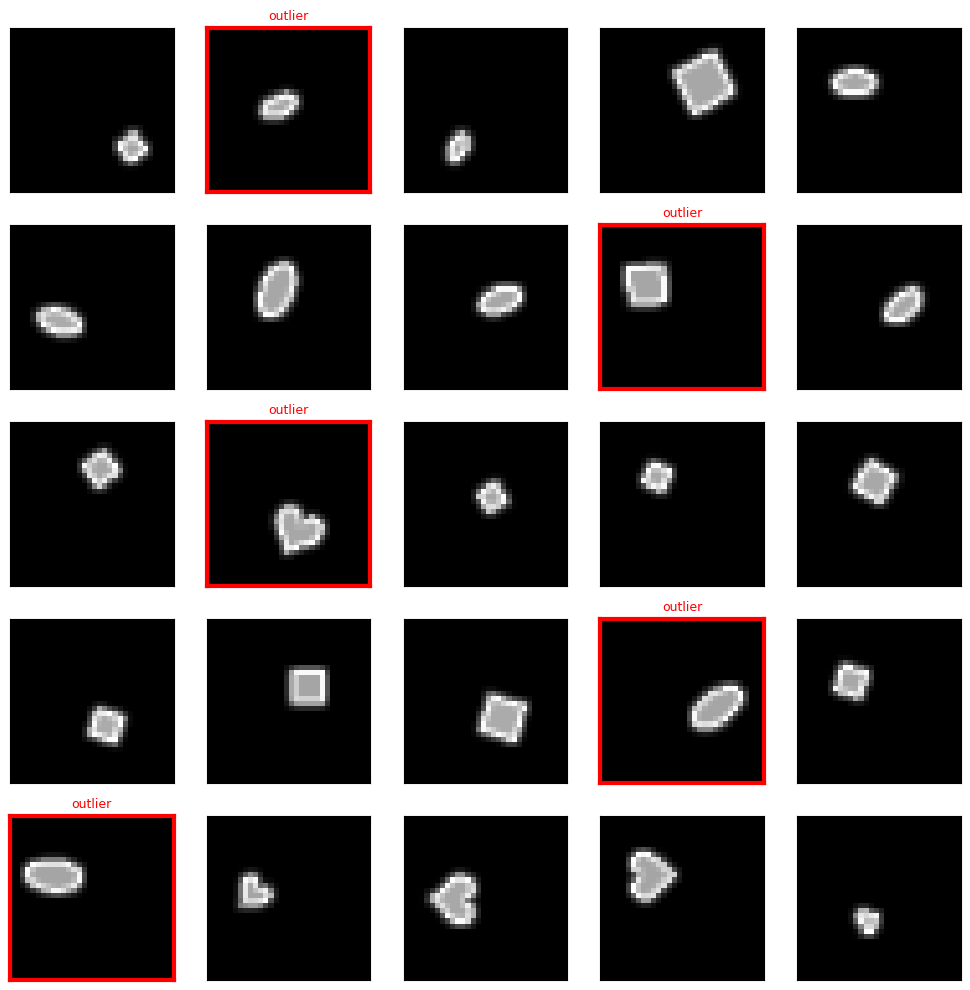

In [ ]:
def plot_groups(x, y, num_groups=5):
    """Plot groups of 5 images. The outlier is highlighted with a red border."""
    fig, axes = plt.subplots(num_groups, 5, figsize=(10, 2 * num_groups))
    for i in range(num_groups):
        for j in range(5):
            axes[i, j].imshow(x[i, j], cmap='gray')
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            if j == y[i]:
                for spine in axes[i, j].spines.values():
                    spine.set_edgecolor('red')
                    spine.set_linewidth(3)
                axes[i, j].set_title('outlier', color='red', fontsize=9)
    plt.tight_layout()
    plt.show()

plot_groups(x, y, num_groups=5)

## Step 2 — Example: Logistic Regression Baseline
Below we apply a simple logistic regression to the flattened input as a demonstration. This model treats the entire group of 5 images as one flat vector and does not use any deep learning.

Note that **random chance** for this 5-class problem is **20%** (1/5).
As you can see, the logistic regression baseline performs close to random chance — you are expected to do significantly better using a deep learning model implemented in PyTorch (or Jax/TensorFlow).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

features = x.reshape(x.shape[0], -1)  # flatten each group of 5 images into a single vector
labels = y

x_train, x_val, y_train, y_val = train_test_split(features, labels, test_size=0.33, random_state=42)

clf = LogisticRegression(max_iter=1000)
clf.fit(x_train, y_train)

predictions = clf.predict(x_val)
accuracy = accuracy_score(y_val, predictions)
print(f'The validation accuracy of the baseline model is {accuracy * 100:.2f}%')

The validation accuracy of the baseline model is 19.39%


## Step 3 — Your Model
This is the main part of your report. Provide your model implementation, training code, and explanation below. Details should include the architecture, choice of hyperparameters, and any preprocessing or augmentation you applied. If you performed a hyperparameter search, explain it here.

**Important:** Your model must have at most **25,000** trainable parameters. You **must** uncomment and run the cell below to print and verify the parameter count. This count must also appear in your report.

In [ ]:
# Imports
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch._utils
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score
import torchvision.transforms as T
from torch.optim.lr_scheduler import CosineAnnealingLR
import copy


  ### Implementation 1: Geometric MLP

In [ ]:

import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

torch.set_num_threads(1)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

GLOBAL_SEED = 42
HOLDOUT_TRAIN_SEED = 1042
REFIT_SEED = 2026
seed_everything(GLOBAL_SEED)
# Keep CPU here to match the GA search exactly and reduce run-to-run drift.
device = torch.device('cpu')

# -----------------------------------------------------------------------------
# Original V4 geometric features (kept fixed).
# The only changes here are in the scorer MLP and training protocol, chosen by a
# compact genetic search around the original V4 family.
# -----------------------------------------------------------------------------

def image_features(img):
    m = img.astype(np.float32)
    if m.max() > 1.0:
        m = m / 255.0
    ys, xs = np.mgrid[:32, :32].astype(np.float32)

    weight = m.sum() + 1e-6
    cx = (m * xs).sum() / weight
    cy = (m * ys).sum() / weight

    dx = xs - cx
    dy = ys - cy

    cov_xx = (m * dx * dx).sum() / weight
    cov_yy = (m * dy * dy).sum() / weight
    cov_xy = (m * dx * dy).sum() / weight

    cov = np.array([[cov_xx, cov_xy], [cov_xy, cov_yy]], dtype=np.float32)
    eigvals = np.linalg.eigvalsh(cov)
    ecc = eigvals[1] / (eigvals[0] + 1e-6)

    area_03 = (m > 0.30).mean()
    area_05 = (m > 0.50).mean()
    mean = m.mean()
    std = m.std()

    radius = np.sqrt(dx * dx + dy * dy)
    ring_features = []
    for lo, hi in [(0, 4), (4, 8), (8, 12), (12, 20)]:
        mask = (radius >= lo) & (radius < hi)
        ring_features.append(m[mask].mean() if mask.any() else 0.0)

    return np.array(
        [
            cx, cy, cov_xx, cov_yy, cov_xy,
            eigvals[0], eigvals[1], ecc,
            area_03, area_05, mean, std,
            *ring_features,
        ],
        dtype=np.float32,
    )


def build_group_features(x_array):
    image_feats = np.stack([[image_features(img) for img in group] for group in x_array])
    groups = []
    for group in image_feats:
        candidates = []
        for i in range(5):
            fi = group[i]
            others = np.delete(group, i, axis=0)
            mu = others.mean(axis=0)
            sd = others.std(axis=0) + 1e-6
            candidates.append(np.concatenate([fi, mu, sd, np.abs(fi - mu), fi * mu], axis=0))
        groups.append(np.stack(candidates))
    return np.stack(groups).astype(np.float32)


class FeatureDataset(Dataset):
    def __init__(self, feats, labels=None, permute_prob=0.0, feature_noise=0.0):
        self.feats = feats.astype(np.float32)
        self.labels = None if labels is None else labels.astype(np.int64)
        self.permute_prob = float(permute_prob)
        self.feature_noise = float(feature_noise)

    def __len__(self):
        return len(self.feats)

    def __getitem__(self, idx):
        x = self.feats[idx].copy()
        if self.labels is None:
            return torch.from_numpy(x)
        y = int(self.labels[idx])
        if self.permute_prob > 0 and np.random.rand() < self.permute_prob:
            perm = np.random.permutation(5)
            x = x[perm]
            y = int(np.where(perm == y)[0][0])
        if self.feature_noise > 0:
            x = x + np.random.normal(0.0, self.feature_noise, size=x.shape).astype(np.float32)
        return torch.from_numpy(x), torch.tensor(y, dtype=torch.long)


class GAOptimizedV4Net(nn.Module):
    def __init__(self, input_dim, h1, h2, h3, act='relu', norm='none', drop1=0.0, drop2=0.0, input_drop=0.0):
        super().__init__()
        self.input_drop = nn.Dropout(input_drop) if input_drop > 0 else nn.Identity()
        self.act_name = act
        dims = [input_dim, h1, h2] + ([] if h3 == 0 else [h3]) + [1]
        layers = []
        num_hidden = len(dims) - 2
        drops = [drop1, drop2, drop2]
        for i in range(num_hidden):
            in_d = dims[i]
            out_d = dims[i + 1]
            layers.append(nn.Linear(in_d, out_d))
            if norm == 'batchnorm':
                layers.append(nn.BatchNorm1d(out_d))
            elif norm == 'layernorm':
                layers.append(nn.LayerNorm(out_d))
            layers.append(self._make_act())
            d = drops[min(i, len(drops) - 1)]
            if d > 0:
                layers.append(nn.Dropout(d))
        layers.append(nn.Linear(dims[-2], 1))
        self.net = nn.Sequential(*layers)

    def _make_act(self):
        if self.act_name == 'relu':
            return nn.ReLU()
        if self.act_name == 'gelu':
            return nn.GELU()
        if self.act_name == 'silu':
            return nn.SiLU()
        raise ValueError(self.act_name)

    def forward(self, x):
        b, n, d = x.shape
        z = self.input_drop(x.view(b * n, d))
        logits = self.net(z)
        return logits.view(b, n)


def odd_margin_loss(logits, targets, margin=0.18):
    true_scores = logits.gather(1, targets[:, None]).squeeze(1)
    mask = F.one_hot(targets, num_classes=logits.shape[1]).bool()
    other_scores = logits.masked_fill(mask, -1e9).max(dim=1).values
    return F.relu(margin - (true_scores - other_scores)).mean()


def standard_scale_fit(train_feats):
    mean = train_feats.mean(axis=(0, 1), keepdims=True)
    std = train_feats.std(axis=(0, 1), keepdims=True) + 1e-6
    return mean.astype(np.float32), std.astype(np.float32)


def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_count = 0
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * len(yb)
            total_correct += (logits.argmax(dim=1) == yb).sum().item()
            total_count += len(yb)
    return total_loss / total_count, total_correct / total_count

# Best GA-selected V4 variant after evaluating the shortlist on the public half.
# This version uses a holdout to pick the training length, then refits on the
# full training set for a slightly longer schedule.
# Add this to BEST_CFG
BEST_CFG = {
    'h1': 128,
    'h2': 64,
    'h3': 0,
    'act': 'silu',
    'norm': 'layernorm',
    'drop1': 0.05,
    'drop2': 0.0,
    'input_drop': 0.0,
    'lr': 0.002,
    'weight_decay': 0.0,   # keep this at 0 when using explicit L2 below
    'l2_lambda': 3e-5,     # start here; try 3e-5 if overfitting remains
    'label_smoothing': 0.08,
    'batch_size': 128,
    'feature_noise': 0.02,
    'permute_prob': 1.0,
    'max_epochs': 65,
    'patience': 9,
    'scheduler': 'none',
    'margin_w': 0.08,
    'margin': 0.18,
    'grad_clip': 0.7,
}

# Add this helper
def l2_penalty(model):
    reg = next(model.parameters()).new_zeros(())
    for module in model.modules():
        if isinstance(module, nn.Linear):
            reg = reg + module.weight.pow(2).sum()
    return reg


def fit_with_holdout(model, train_loader, val_loader, cfg):
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg['label_smoothing'])
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=cfg['lr'],
        weight_decay=cfg['weight_decay'],
    )
    best_val_acc = 0.0
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    for epoch in range(1, cfg['max_epochs'] + 1):
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_count = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)

            base_loss = (
                criterion(logits, yb)
                + cfg['margin_w'] * odd_margin_loss(logits, yb, margin=cfg['margin'])
            )
            loss = base_loss + cfg['l2_lambda'] * l2_penalty(model)

            loss.backward()
            if cfg['grad_clip'] > 0:
                nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            optimizer.step()

            running_loss += loss.item() * len(yb)
            running_correct += (logits.argmax(dim=1) == yb).sum().item()
            running_count += len(yb)

        train_loss = running_loss / running_count
        train_acc = running_correct / running_count
        val_loss, val_acc = evaluate(model, val_loader)

        print(
            f"Epoch {epoch:02d}/{cfg['max_epochs']} | "
            f"train loss={train_loss:.4f} | train acc={train_acc:.4f} | "
            f"val loss={val_loss:.4f} | val acc={val_acc:.4f}"
        )

        if val_acc > best_val_acc + 1e-12:
            best_val_acc = val_acc
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= cfg['patience']:
                print('Early stopping triggered.')
                break

    model.load_state_dict(best_state)
    print(f'Best validation accuracy: {best_val_acc * 100:.2f}% at epoch {best_epoch}')
    return model, best_val_acc, best_epoch


def refit_on_full_data(model, train_loader, cfg, epochs):
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg['label_smoothing'])
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=cfg['lr'],
        weight_decay=cfg['weight_decay'],
    )

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_count = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)

            base_loss = (
                criterion(logits, yb)
                + cfg['margin_w'] * odd_margin_loss(logits, yb, margin=cfg['margin'])
            )
            loss = base_loss + cfg['l2_lambda'] * l2_penalty(model)

            loss.backward()
            if cfg['grad_clip'] > 0:
                nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            optimizer.step()

            running_loss += loss.item() * len(yb)
            running_correct += (logits.argmax(dim=1) == yb).sum().item()
            running_count += len(yb)

        print(
            f"Refit epoch {epoch:02d}/{epochs:02d} | "
            f"train loss={running_loss / running_count:.4f} | "
            f"train acc={running_correct / running_count:.4f}"
        )
    return model


@torch.no_grad()
def predict_numpy(model, x_array, batch_size=256):
    model.eval()
    pred_features = build_group_features(x_array)
    pred_features = (pred_features - feature_mean) / feature_std
    pred_loader = DataLoader(
        FeatureDataset(pred_features, labels=None, permute_prob=0.0, feature_noise=0.0),
        batch_size=batch_size,
        shuffle=False,
    )
    preds = []
    for xb in pred_loader:
        xb = xb.to(device)
        preds.append(model(xb).argmax(dim=1).cpu().numpy())
    return np.concatenate(preds)


all_features = build_group_features(x)
feat_dim = all_features.shape[-1]

train_idx, val_idx = train_test_split(
    np.arange(len(all_features)),
    test_size=0.15,
    random_state=42,
    stratify=y,
)

split_mean, split_std = standard_scale_fit(all_features[train_idx])
split_features = (all_features - split_mean) / split_std

seed_everything(HOLDOUT_TRAIN_SEED)
train_loader = DataLoader(
    FeatureDataset(split_features[train_idx], y[train_idx], permute_prob=BEST_CFG['permute_prob'], feature_noise=BEST_CFG['feature_noise']),
    batch_size=BEST_CFG['batch_size'],
    shuffle=True,
)
val_loader = DataLoader(
    FeatureDataset(split_features[val_idx], y[val_idx], permute_prob=0.0, feature_noise=0.0),
    batch_size=256,
    shuffle=False,
)

model = GAOptimizedV4Net(
    feat_dim,
    BEST_CFG['h1'], BEST_CFG['h2'], BEST_CFG['h3'],
    BEST_CFG['act'], BEST_CFG['norm'],
    BEST_CFG['drop1'], BEST_CFG['drop2'], BEST_CFG['input_drop'],
).to(device)

if globals().get('_DRY_RUN_ONLY_', False):
    feature_mean = all_features.mean(axis=(0, 1), keepdims=True)
    feature_std = all_features.std(axis=(0, 1), keepdims=True) + 1e-6
    print('Dry-run mode: skipping full training.')
else:
    model, best_val_acc, best_epoch = fit_with_holdout(model, train_loader, val_loader, BEST_CFG)
    refit_epochs = max(20, int(round(best_epoch * 1.05)))
    print(f'\nRefitting on the full training set for {refit_epochs} epochs...')

    seed_everything(REFIT_SEED)
    feature_mean, feature_std = standard_scale_fit(all_features)
    full_features = (all_features - feature_mean) / feature_std
    full_loader = DataLoader(
        FeatureDataset(full_features, y, permute_prob=BEST_CFG['permute_prob'], feature_noise=BEST_CFG['feature_noise']),
        batch_size=BEST_CFG['batch_size'],
        shuffle=True,
    )

    model = GAOptimizedV4Net(
        feat_dim,
        BEST_CFG['h1'], BEST_CFG['h2'], BEST_CFG['h3'],
        BEST_CFG['act'], BEST_CFG['norm'],
        BEST_CFG['drop1'], BEST_CFG['drop2'], BEST_CFG['input_drop'],
    ).to(device)
    model = refit_on_full_data(model, full_loader, BEST_CFG, refit_epochs)


Epoch 01/65 | train loss=1.0931 | train acc=0.6933 | val loss=0.7925 | val acc=0.7733
Epoch 02/65 | train loss=0.8035 | train acc=0.8349 | val loss=0.6822 | val acc=0.8133
Epoch 03/65 | train loss=0.7243 | train acc=0.8518 | val loss=0.6229 | val acc=0.8133
Epoch 04/65 | train loss=0.6925 | train acc=0.8588 | val loss=0.6022 | val acc=0.8222
Epoch 05/65 | train loss=0.6631 | train acc=0.8714 | val loss=0.5838 | val acc=0.8222
Epoch 06/65 | train loss=0.6469 | train acc=0.8773 | val loss=0.5594 | val acc=0.8356
Epoch 07/65 | train loss=0.6310 | train acc=0.8835 | val loss=0.5549 | val acc=0.8311
Epoch 08/65 | train loss=0.6198 | train acc=0.8863 | val loss=0.5320 | val acc=0.8356
Epoch 09/65 | train loss=0.6184 | train acc=0.8824 | val loss=0.5462 | val acc=0.8378
Epoch 10/65 | train loss=0.6017 | train acc=0.8953 | val loss=0.5325 | val acc=0.8333
Epoch 11/65 | train loss=0.6099 | train acc=0.8871 | val loss=0.5419 | val acc=0.8333
Epoch 12/65 | train loss=0.5934 | train acc=0.8953 | v

###Implementation 2: Geometric Descriptor MLP model

In [ ]:
# ============================================================
# - 59-D geometric descriptor per tile = fft53 + dist6
# - RelationSigmaMLP relation model
# - Weighted bootstrap loss + odd-margin loss + tiny L1
# - 20-epoch full-data refit after holdout selection
# - 4-view descriptor TTA with variant-specific normalization
# Expected parameter count: 21,857
# ============================================================

from pathlib import Path
import copy
import math
import random
import warnings

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import assignment3_tta_helper as tta_helper
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings('ignore')
cv2.setNumThreads(1)
torch.set_num_threads(1)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


GLOBAL_SEED = 42
HOLDOUT_TRAIN_SEED = 1042
REFIT_SEED = 2026
seed_everything(GLOBAL_SEED)
device = torch.device('cpu')

BEST_CFG = {
    'lr': 0.002,
    'weight_decay': 0.0,
    'l2_lambda': 3e-5,
    'l1_lambda': 3e-6,
    'label_smoothing': 0.06,
    'batch_size': 128,
    'feature_noise': 0.02,
    'permute_prob': 1.0,
    'max_epochs': 30,
    'patience': 6,
    'margin_w': 0.08,
    'margin': 0.18,
    'grad_clip': 0.7,
}

EXTRACT_SIZE = 256
MORPH_KERNEL = np.ones((3, 3), np.uint8)
GRID_YS, GRID_XS = np.mgrid[:EXTRACT_SIZE, :EXTRACT_SIZE].astype(np.float32)
RING_BOUNDS = [(0, 16), (16, 32), (32, 48), (48, 72), (72, 96), (96, 128)]
TARGET_RADIUS = 0.78 * ((EXTRACT_SIZE - 1) / 2.0)
CACHE_DIR = Path('shape_cache')
CACHE_DIR.mkdir(exist_ok=True)
TRAIN_FEAT_CACHE = CACHE_DIR / 'assignment3_best_feat59_train_v1.npz'
TEST_FEAT_CACHE = CACHE_DIR / 'assignment3_best_feat59_test_v1.npz'
_PRED_FEAT_CACHE = {}


def _to_u8(img):
    if img.dtype == np.uint8:
        return img
    return np.clip(img, 0, 255).astype(np.uint8)


def extract_outline_and_mask(img):
    img = _to_u8(img)
    big = cv2.resize(img, (EXTRACT_SIZE, EXTRACT_SIZE), interpolation=cv2.INTER_CUBIC)
    blur = cv2.GaussianBlur(big, (5, 5), 0)
    _, mask = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, MORPH_KERNEL, iterations=1)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    outline = np.zeros_like(big)
    cnt = None
    if contours:
        cnt = max(contours, key=cv2.contourArea)
        cv2.drawContours(outline, [cnt], -1, 255, 2, lineType=cv2.LINE_AA)
    return outline, mask, cnt


def hu_moments_from_mask(mask):
    moments = cv2.moments(mask)
    hu = cv2.HuMoments(moments).flatten().astype(np.float32)
    return np.sign(hu) * np.log1p(np.abs(hu))


def dice_sym(mask01, other01):
    inter = float((mask01 * other01).sum())
    denom = float(mask01.sum() + other01.sum()) + 1e-6
    return 2.0 * inter / denom


def center_scale_mask(cnt, cx, cy):
    pts = cnt[:, 0, :].astype(np.float32)
    rad = np.sqrt((pts[:, 0] - cx) ** 2 + (pts[:, 1] - cy) ** 2)
    max_r = float(rad.max() + 1e-6)
    scale = TARGET_RADIUS / max_r
    center = np.array([(EXTRACT_SIZE - 1) / 2.0, (EXTRACT_SIZE - 1) / 2.0], dtype=np.float32)
    tpts = (pts - np.array([cx, cy], dtype=np.float32)) * scale + center
    tpts = np.round(tpts).astype(np.int32)
    tpts[:, 0] = np.clip(tpts[:, 0], 0, EXTRACT_SIZE - 1)
    tpts[:, 1] = np.clip(tpts[:, 1], 0, EXTRACT_SIZE - 1)
    norm_mask = np.zeros((EXTRACT_SIZE, EXTRACT_SIZE), np.uint8)
    cv2.fillPoly(norm_mask, [tpts], 255)
    return norm_mask


def radial_signature(norm_mask, bins=32):
    cy = (EXTRACT_SIZE - 1) / 2.0
    cx = (EXTRACT_SIZE - 1) / 2.0
    edge = cv2.Canny(norm_mask, 64, 128)
    ys, xs = np.nonzero(edge > 0)
    if len(xs) == 0:
        return np.zeros(bins, dtype=np.float32)

    ang = np.arctan2(ys - cy, xs - cx)
    rad = np.sqrt((ys - cy) ** 2 + (xs - cx) ** 2)
    ids = ((ang + np.pi) / (2.0 * np.pi) * bins).astype(np.int32) % bins

    sig = np.zeros(bins, dtype=np.float32)
    counts = np.zeros(bins, dtype=np.float32)
    for idx, rr in zip(ids, rad):
        sig[idx] += rr
        counts[idx] += 1

    mean_rad = float(rad.mean()) if len(rad) else 1.0
    for i in range(bins):
        sig[i] = sig[i] / counts[i] if counts[i] > 0 else mean_rad

    sig /= max(float(sig.mean()), 1e-6)
    return sig.astype(np.float32)


def dist_features(mask):
    bin_mask = (mask > 0).astype(np.uint8)
    if bin_mask.sum() == 0:
        return np.zeros(6, dtype=np.float32)

    dist = cv2.distanceTransform(bin_mask, cv2.DIST_L2, 5).astype(np.float32)
    inside = dist[bin_mask > 0]
    mx = float(inside.max()) + 1e-6
    norm = inside / mx
    return np.array(
        [
            inside.mean() / EXTRACT_SIZE,
            inside.std() / EXTRACT_SIZE,
            inside.max() / EXTRACT_SIZE,
            float((norm >= 0.25).mean()),
            float((norm >= 0.50).mean()),
            float((norm >= 0.75).mean()),
        ],
        dtype=np.float32,
    )


def extract_tile_features(img):
    outline, mask, cnt = extract_outline_and_mask(img)
    if cnt is None or len(cnt) < 5:
        return np.zeros(59, np.float32)

    area = float(cv2.contourArea(cnt))
    perim = float(cv2.arcLength(cnt, True))
    _, _, w, h = cv2.boundingRect(cnt)
    hull = cv2.convexHull(cnt)
    hull_area = float(cv2.contourArea(hull)) + 1e-6
    rect_area = float(w * h) + 1e-6

    moments = cv2.moments(cnt)
    cx = moments['m10'] / (moments['m00'] + 1e-6)
    cy = moments['m01'] / (moments['m00'] + 1e-6)

    try:
        (_, _), (MA, ma), angle_deg = cv2.fitEllipse(cnt)
        major = max(MA, ma)
        minor = min(MA, ma)
    except cv2.error:
        angle_deg = 0.0
        major = float(max(w, h))
        minor = float(min(w, h))

    ecc = major / (minor + 1e-6)
    pts = cnt[:, 0, :].astype(np.float32)
    rad = np.sqrt((pts[:, 0] - cx) ** 2 + (pts[:, 1] - cy) ** 2)
    q = np.quantile(rad, [0.1, 0.25, 0.5, 0.75, 0.9]).astype(np.float32)

    rr = np.sqrt((GRID_XS - cx) ** 2 + (GRID_YS - cy) ** 2)
    mask01 = (mask > 0).astype(np.float32)
    ring = []
    for lo, hi in RING_BOUNDS:
        mk = (rr >= lo) & (rr < hi)
        ring.append(float(mask01[mk].mean()) if mk.any() else 0.0)

    out = outline.astype(np.float32) / 255.0
    wsum = out.sum() + 1e-6
    ocx = (out * GRID_XS).sum() / wsum
    ocy = (out * GRID_YS).sum() / wsum
    dx = GRID_XS - ocx
    dy = GRID_YS - ocy
    cov_xx = (out * dx * dx).sum() / wsum
    cov_yy = (out * dy * dy).sum() / wsum
    cov_xy = (out * dx * dy).sum() / wsum
    cov = np.array([[cov_xx, cov_xy], [cov_xy, cov_yy]], dtype=np.float32)
    eigvals = np.linalg.eigvalsh(cov)

    norm_mask = center_scale_mask(cnt, cx, cy)
    norm01 = (norm_mask > 127).astype(np.float32)
    vertical_sym = dice_sym(norm01, np.fliplr(norm01).copy())
    horizontal_sym = dice_sym(norm01, np.flipud(norm01).copy())
    rot180_sym = dice_sym(norm01, norm01[::-1, ::-1].copy())
    best_sym = max(vertical_sym, horizontal_sym, rot180_sym)
    asym = 1.0 - best_sym
    theta = math.radians(float(angle_deg))
    gated_cos = asym * math.cos(2.0 * theta)
    gated_sin = asym * math.sin(2.0 * theta)

    hu = hu_moments_from_mask(mask)
    sig = radial_signature(norm_mask, bins=32)
    fft = np.abs(np.fft.rfft(sig - sig.mean()))[1:7].astype(np.float32)
    dist6 = dist_features(mask)

    base47 = np.array(
        [
            cx / 255.0,
            cy / 255.0,
            area / (EXTRACT_SIZE * EXTRACT_SIZE),
            perim / (EXTRACT_SIZE * 4.0),
            w / EXTRACT_SIZE,
            h / EXTRACT_SIZE,
            w / (h + 1e-6),
            area / rect_area,
            area / hull_area,
            ecc,
            major / EXTRACT_SIZE,
            minor / EXTRACT_SIZE,
            rad.mean() / EXTRACT_SIZE,
            rad.std() / EXTRACT_SIZE,
            rad.min() / EXTRACT_SIZE,
            rad.max() / EXTRACT_SIZE,
            *list(q / EXTRACT_SIZE),
            *ring,
            out.mean(),
            best_sym,
            asym,
            ocx / 255.0,
            ocy / 255.0,
            cov_xx / (EXTRACT_SIZE * EXTRACT_SIZE),
            cov_yy / (EXTRACT_SIZE * EXTRACT_SIZE),
            cov_xy / (EXTRACT_SIZE * EXTRACT_SIZE),
            eigvals[0] / (EXTRACT_SIZE * EXTRACT_SIZE),
            eigvals[1] / (EXTRACT_SIZE * EXTRACT_SIZE),
            eigvals[1] / (eigvals[0] + 1e-6),
            gated_cos,
            gated_sin,
            *list(hu),
        ],
        dtype=np.float32,
    )
    return np.concatenate([base47, fft, dist6], axis=0).astype(np.float32)


def extract_feature_pack(x_array, cache_path=None):
    if cache_path is not None and cache_path.exists():
        cached = np.load(cache_path)
        if cached['feat59'].shape[:2] == x_array.shape[:2]:
            print(f'Loaded cached features from {cache_path}')
            return cached['feat59'].astype(np.float32)

    feat59 = np.zeros((len(x_array), 5, 59), dtype=np.float32)
    for gi, group in enumerate(x_array):
        for ii, img in enumerate(group):
            feat59[gi, ii] = extract_tile_features(img)
        if (gi + 1) % 250 == 0 or gi + 1 == len(x_array):
            print(f'Extracted features for {gi + 1}/{len(x_array)} groups')

    if cache_path is not None:
        np.savez_compressed(cache_path, feat59=feat59)
        print(f'Saved cache to {cache_path}')
    return feat59


def standard_scale_fit(train_feats):
    mean = train_feats.mean(axis=(0, 1), keepdims=True)
    std = train_feats.std(axis=(0, 1), keepdims=True) + 1e-6
    return mean.astype(np.float32), std.astype(np.float32)


def compute_ambiguity_weights(tile_feats):
    pairwise = np.sqrt(((tile_feats[:, :, None, :] - tile_feats[:, None, :, :]) ** 2).sum(axis=-1))
    oddness = pairwise.sum(axis=2)
    ranked = np.sort(oddness, axis=1)
    margins = ranked[:, -1] - ranked[:, -2]
    weights = 0.35 + 0.65 * (margins - margins.min()) / (margins.max() - margins.min() + 1e-6)
    return weights.astype(np.float32)


class FeatureDataset(Dataset):
    def __init__(self, feats, labels=None, permute_prob=0.0, feature_noise=0.0):
        self.feats = feats.astype(np.float32)
        self.labels = None if labels is None else labels.astype(np.int64)
        self.permute_prob = float(permute_prob)
        self.feature_noise = float(feature_noise)

    def __len__(self):
        return len(self.feats)

    def __getitem__(self, idx):
        x_feat = self.feats[idx].copy()
        if self.labels is None:
            return torch.from_numpy(x_feat)
        y_label = int(self.labels[idx])
        if self.permute_prob > 0 and np.random.rand() < self.permute_prob:
            perm = np.random.permutation(5)
            x_feat = x_feat[perm]
            y_label = int(np.where(perm == y_label)[0][0])
        if self.feature_noise > 0:
            x_feat = x_feat + np.random.normal(0.0, self.feature_noise, size=x_feat.shape).astype(np.float32)
        return torch.from_numpy(x_feat), torch.tensor(y_label, dtype=torch.long)


class WeightedFeatureDataset(Dataset):
    def __init__(self, feats, weights, labels, permute_prob=0.0, feature_noise=0.0):
        self.feats = feats.astype(np.float32)
        self.weights = weights.astype(np.float32)
        self.labels = labels.astype(np.int64)
        self.permute_prob = float(permute_prob)
        self.feature_noise = float(feature_noise)

    def __len__(self):
        return len(self.feats)

    def __getitem__(self, idx):
        x_feat = self.feats[idx].copy()
        y_label = int(self.labels[idx])
        weight = float(self.weights[idx])
        if self.permute_prob > 0 and np.random.rand() < self.permute_prob:
            perm = np.random.permutation(5)
            x_feat = x_feat[perm]
            y_label = int(np.where(perm == y_label)[0][0])
        if self.feature_noise > 0:
            x_feat = x_feat + np.random.normal(0.0, self.feature_noise, size=x_feat.shape).astype(np.float32)
        return (
            torch.from_numpy(x_feat),
            torch.tensor(y_label, dtype=torch.long),
            torch.tensor(weight, dtype=torch.float32),
        )


class RelationSigmaMLP(nn.Module):
    def __init__(self, input_dim, enc1=64, enc2=32, rel_hidden=96, drop=0.05):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, enc1),
            nn.LayerNorm(enc1),
            nn.SiLU(),
            nn.Dropout(drop),
            nn.Linear(enc1, enc2),
            nn.LayerNorm(enc2),
            nn.SiLU(),
        )
        self.head = nn.Sequential(
            nn.Linear(enc2 * 5, rel_hidden),
            nn.LayerNorm(rel_hidden),
            nn.SiLU(),
            nn.Dropout(drop),
            nn.Linear(rel_hidden, 1),
        )

    def forward(self, tile_feat):
        bsz, n_items, feat_dim = tile_feat.shape
        z = self.encoder(tile_feat.reshape(bsz * n_items, feat_dim)).reshape(bsz, n_items, -1)
        mu = (z.sum(dim=1, keepdim=True) - z) / (n_items - 1)
        others = []
        for i in range(n_items):
            others.append(torch.cat([z[:, :i], z[:, i + 1:]], dim=1))
        others = torch.stack(others, dim=1)
        sd = others.std(dim=2, unbiased=False)
        rel = torch.cat([z, mu, sd, torch.abs(z - mu), z * mu], dim=-1)
        return self.head(rel).squeeze(-1)


class WeightedBootstrapLoss(nn.Module):
    def __init__(self, beta=0.90, smoothing=0.04):
        super().__init__()
        self.beta = beta
        self.smoothing = smoothing

    def forward(self, logits, targets, sample_weight):
        probs = torch.softmax(logits, dim=1)
        one_hot = torch.zeros_like(probs).scatter_(1, targets[:, None], 1.0)
        smooth = one_hot * (1.0 - self.smoothing) + self.smoothing / probs.size(1)
        boot_targets = self.beta * smooth + (1.0 - self.beta) * probs.detach()
        per_sample = -(boot_targets * torch.log_softmax(logits, dim=1)).sum(dim=1)
        return (sample_weight * per_sample).mean()


def odd_margin_loss(logits, targets, margin=0.18):
    true_scores = logits.gather(1, targets[:, None]).squeeze(1)
    mask = F.one_hot(targets, num_classes=logits.shape[1]).bool()
    other_scores = logits.masked_fill(mask, -1e9).max(dim=1).values
    return F.relu(margin - (true_scores - other_scores)).mean()


def l2_penalty(model):
    reg = next(model.parameters()).new_zeros(())
    for module in model.modules():
        if isinstance(module, nn.Linear):
            reg = reg + module.weight.pow(2).sum()
    return reg


def l1_penalty(model):
    reg = next(model.parameters()).new_zeros(())
    for module in model.modules():
        if isinstance(module, nn.Linear):
            reg = reg + module.weight.abs().sum()
    return reg


def evaluate(model, loader):
    model.eval()
    total_correct = 0
    total_count = 0
    with torch.no_grad():
        for batch in loader:
            xb, yb = batch[:2]
            xb = xb.to(device)
            yb = yb.to(device)
            logits = model(xb)
            total_correct += (logits.argmax(dim=1) == yb).sum().item()
            total_count += len(yb)
    return total_correct / total_count


def fit_with_holdout(model, train_loader, val_loader, cfg):
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg['label_smoothing'])
    boot_loss = WeightedBootstrapLoss(beta=0.90, smoothing=min(cfg['label_smoothing'], 0.04))
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])

    best_val_acc = 0.0
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())
    bad_epochs = 0

    for epoch in range(1, cfg['max_epochs'] + 1):
        model.train()
        for xb, yb, wb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)
            wb = wb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            base_loss = boot_loss(logits, yb, wb) + cfg['margin_w'] * odd_margin_loss(logits, yb, margin=cfg['margin'])
            loss = base_loss + cfg['l2_lambda'] * l2_penalty(model) + cfg['l1_lambda'] * l1_penalty(model)
            loss.backward()
            if cfg['grad_clip'] > 0:
                nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            optimizer.step()

        val_acc = evaluate(model, val_loader)
        print(f"Epoch {epoch:02d}/{cfg['max_epochs']} | val acc={val_acc:.4f}")
        if val_acc > best_val_acc + 1e-12:
            best_val_acc = val_acc
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= cfg['patience']:
                print('Early stopping triggered.')
                break

    model.load_state_dict(best_state)
    return model, best_val_acc, best_epoch


def refit_on_full_data(model, train_loader, cfg, epochs):
    boot_loss = WeightedBootstrapLoss(beta=0.90, smoothing=min(cfg['label_smoothing'], 0.04))
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])

    for epoch in range(1, epochs + 1):
        model.train()
        running_correct = 0
        running_count = 0
        for xb, yb, wb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)
            wb = wb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            base_loss = boot_loss(logits, yb, wb) + cfg['margin_w'] * odd_margin_loss(logits, yb, margin=cfg['margin'])
            loss = base_loss + cfg['l2_lambda'] * l2_penalty(model) + cfg['l1_lambda'] * l1_penalty(model)
            loss.backward()
            if cfg['grad_clip'] > 0:
                nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            optimizer.step()
            running_correct += (logits.argmax(dim=1) == yb).sum().item()
            running_count += len(yb)
        print(f"Refit epoch {epoch:02d}/{epochs:02d} | train acc={running_correct / running_count:.4f}")

    return model


def features_for_prediction(x_array):
    key = (x_array.shape, x_array.dtype.str, hash(x_array[: min(len(x_array), 32)].tobytes()))
    if key in _PRED_FEAT_CACHE:
        return _PRED_FEAT_CACHE[key]
    feats = extract_feature_pack(x_array, cache_path=None)
    _PRED_FEAT_CACHE[key] = feats
    return feats


@torch.no_grad()
def predict_logits_from_features(model, pred_feats, batch_size=256):
    model.eval()
    pred_loader = DataLoader(
        FeatureDataset(pred_feats, labels=None, permute_prob=0.0, feature_noise=0.0),
        batch_size=batch_size,
        shuffle=False,
    )
    logits = []
    for xb in pred_loader:
        xb = xb.to(device)
        logits.append(model(xb).cpu().numpy())
    return np.concatenate(logits, axis=0)


USE_DESCRIPTOR_TTA = True
TTA_VARIANTS = ['blur04', 'blur06', 'blur06_c0']


@torch.no_grad()
def predict_numpy(model, x_array, batch_size=256):
    model.eval()
    pred_feats = features_for_prediction(x_array)
    pred_feats = (pred_feats - feature_mean) / feature_std
    base_logits = predict_logits_from_features(model, pred_feats, batch_size=batch_size)
    if not USE_DESCRIPTOR_TTA:
        return base_logits.argmax(axis=1)

    logits_list = [base_logits]
    for variant_name in TTA_VARIANTS:
        variant_mean, variant_std = variant_feature_stats[variant_name]
        logits_list.append(
            tta_helper.predict_variant_logits(
                model,
                x_array,
                variant_mean,
                variant_std,
                device,
                variant_name=variant_name,
                batch_size=batch_size,
            )
        )
    final_logits = np.mean(logits_list, axis=0)
    return final_logits.argmax(axis=1)


class NotebookPredictor:
    def __init__(self, model):
        self.model = model

    def predict(self, flat_or_group_array):
        arr = np.asarray(flat_or_group_array)
        if arr.ndim == 2 and arr.shape[1] == 5 * 32 * 32:
            arr = arr.reshape(-1, 5, 32, 32)
        elif arr.ndim == 4 and arr.shape[1:] == (5, 32, 32):
            pass
        else:
            raise ValueError('Expected shape (n, 5120) or (n, 5, 32, 32).')
        return predict_numpy(self.model, arr)


x = np.load('datasets/x_train.npy')
y = np.load('datasets/y_train.npy')

all_features_raw = extract_feature_pack(x, cache_path=TRAIN_FEAT_CACHE)
train_idx, val_idx = train_test_split(
    np.arange(len(all_features_raw)), test_size=0.15, random_state=42, stratify=y
)

holdout_mean, holdout_std = standard_scale_fit(all_features_raw[train_idx])
holdout_features = (all_features_raw - holdout_mean) / holdout_std
holdout_weights = compute_ambiguity_weights(holdout_features)
feat_dim = holdout_features.shape[-1]

seed_everything(HOLDOUT_TRAIN_SEED)
train_loader = DataLoader(
    WeightedFeatureDataset(
        holdout_features[train_idx],
        holdout_weights[train_idx],
        y[train_idx],
        permute_prob=BEST_CFG['permute_prob'],
        feature_noise=BEST_CFG['feature_noise'],
    ),
    batch_size=BEST_CFG['batch_size'],
    shuffle=True,
)
val_loader = DataLoader(
    FeatureDataset(holdout_features[val_idx], y[val_idx], permute_prob=0.0, feature_noise=0.0),
    batch_size=256,
    shuffle=False,
)

model = RelationSigmaMLP(feat_dim).to(device)
model, best_val_acc, best_epoch = fit_with_holdout(model, train_loader, val_loader, BEST_CFG)
refit_epochs = 20
print(f'Best validation accuracy: {best_val_acc * 100:.2f}% at epoch {best_epoch}')
print(f'Refitting on the full training set for {refit_epochs} epochs...')

seed_everything(REFIT_SEED)
feature_mean, feature_std = standard_scale_fit(all_features_raw)
variant_feature_stats = {}
for variant_name in TTA_VARIANTS:
    variant_cache = CACHE_DIR / f'assignment3_{variant_name}_train_feat59_v1.npy'
    variant_train_features = tta_helper.load_or_extract_variant_features(
        variant_name,
        x,
        cache_path=variant_cache,
    )
    variant_feature_stats[variant_name] = standard_scale_fit(variant_train_features)
full_features = (all_features_raw - feature_mean) / feature_std
full_weights = compute_ambiguity_weights(full_features)
full_loader = DataLoader(
    WeightedFeatureDataset(
        full_features,
        full_weights,
        y,
        permute_prob=BEST_CFG['permute_prob'],
        feature_noise=BEST_CFG['feature_noise'],
    ),
    batch_size=BEST_CFG['batch_size'],
    shuffle=True,
)

model = RelationSigmaMLP(feat_dim).to(device)
model = refit_on_full_data(model, full_loader, BEST_CFG, refit_epochs)
model_predictor = NotebookPredictor(model)


In [ ]:
# ============================================================
# REQUIRED: Print the number of trainable parameters in your model.
# Replace `model` with the name of your PyTorch model.
# This cell MUST appear with its output in your submitted notebook.
# ============================================================

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total trainable parameters: {total_params:,}')
assert total_params <= 25_000, f'Model too large! {total_params:,} > 25,000'

Total trainable parameters: 19,073


### Implementation 3: CNN Approach

Here we apply a **Siamese Neural Network**. This is a model that works in two steps:

1.   Convert images into vector embeddings describing the image using a Convolutional Neural Network (CNN).

2.   Classify the embeddings to find the most probable outlier amongst the embedding. We calculate the mean embedding amongst the images and compute the difference between the instances and the mean. Here we could use mutiple approaches to classify:

*   **Logistic Regression.** **Pros**: Simple, few parameters (we can put more parameters in the CNN)
**Cons**: Linear boundaries.
*   **MLP classifier.** **Pros**: Can learn non-linear boundaries.
**Cons**: More parameters, need to be careful of the limit (Still can use a small MLP)

We also can explore multiple distance metrics before the classification step like:
*   $L_1$
*   $L_2$
*   Cosine similarity
*   Learned metrics (Using a MLP to find a non-linear distance relation)












#### Preprocessing

In [ ]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

# Load the Raw Data
x_train_full = np.load('datasets/x_train.npy')  # Shape: (3000, 5, 32, 32)
y_train_full = np.load('datasets/y_train.npy')  # Shape: (3000)

x_test = np.load('datasets/x_test.npy')         # Shape: (2000, 5, 32, 32)

# Reshape for PyTorch (add channels dimension)
# New shape: (X000, 5, 1, 32, 32)
x_train_full = np.expand_dims(x_train_full, axis=2)
x_test = np.expand_dims(x_test, axis=2)

# Normalize Pixel Values (Speed up training)
if x_train_full.max() > 1.0:
    x_train_full = x_train_full.astype(np.float32) / 255.0
    x_test = x_test.astype(np.float32) / 255.0
else:
    x_train_full = x_train_full.astype(np.float32)
    x_test = x_test.astype(np.float32)

# Create an internal Validation Split
TEST_SIZE = 0.15
SEED = 42
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y_train_full
)

# Convert to PyTorch Tensors
x_train_tensor = torch.tensor(x_train)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

x_val_tensor = torch.tensor(x_val)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

x_test_tensor = torch.tensor(x_test)

# Create PyTorch DataLoaders
BATCH_SIZE = 64

train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

val_dataset = TensorDataset(x_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# For testing, we only have inputs (no labels), so we wrap just the x_test_tensor
test_dataset = TensorDataset(x_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")

Train batches: 40 | Val batches: 8


#### Base CNN Model (3 Versions)

In [ ]:
class BaseCNN_V3(nn.Module):
    def __init__(self, embedding_dim=16):
        super(BaseCNN_V3, self).__init__()

        # Layer 1: Now takes 3 channels! (Grayscale, X-coords, Y-coords)
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Layer 2: 32 -> 64 (Unchanged)
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Dual Pooling (CatPool)
        self.max_pool = nn.MaxPool2d(kernel_size=8)
        self.avg_pool = nn.AvgPool2d(kernel_size=8)

        self.fc = nn.Linear(128, embedding_dim)

    def forward(self, x):
        batch_size, channels, height, width = x.size()

        # CoordConv Logic: Create X and Y channels
        # Generate grids from -1.0 to 1.0
        y_coords = torch.linspace(-1, 1, height).view(1, 1, height, 1).expand(batch_size, 1, height, width).to(x.device)
        x_coords = torch.linspace(-1, 1, width).view(1, 1, 1, width).expand(batch_size, 1, height, width).to(x.device)

        # Concatenate them to the input image (now 3 channels instead of 1)
        x = torch.cat([x, x_coords, y_coords], dim=1)

        # Standard Forward Pass
        x = self.conv1(x)
        x = self.conv2(x)

        # CatPool Logic
        x_max = self.max_pool(x)
        x_avg = self.avg_pool(x)

        # Flatten both pools from (Batch, 64, 1, 1) to (Batch, 64)
        x_max = torch.flatten(x_max, start_dim=1)
        x_avg = torch.flatten(x_avg, start_dim=1)

        # Concatenate to (Batch, 128)
        x_pooled = torch.cat([x_max, x_avg], dim=1)

        # Final Embedding
        embedding = self.fc(x_pooled)
        return embedding

#### Siamese Neural Network

In [ ]:
class SiameseNetwork(nn.Module):
    def __init__(self, base_cnn, embedding_dim=16, drop_percent=0.2, classifier_type='mlp', distance_metric='learned'):
        """
        Args:
            base_cnn: The BaseCNN model we previously defined.
            embedding_dim: The size of the feature vector output by the base_cnn (default 16).
            drop_percent: The dropout percentage.
            classifier_type: 'logistic_regression' or 'mlp'.
            distance_metric: 'l1', 'l2', 'cosine', or 'learned'.
        """
        super(SiameseNetwork, self).__init__()

        self.base_cnn = base_cnn
        self.distance_metric = distance_metric
        self.classifier_type = classifier_type

        # Determine the input size for the classifier
        # If we use the 'learned' metric, we concatenate the mean and the instance, so the input size doubles.
        if self.distance_metric == 'learned':
            classifier_input_dim = embedding_dim * 2
        else:
            classifier_input_dim = embedding_dim

        # Build the Classifier Head
        if self.classifier_type == 'logistic_regression':
            self.classifier = nn.Linear(classifier_input_dim, 1)

        elif self.classifier_type == 'mlp':
            # A more expressive Multi-Layer Perceptron for non-linear classification
            if self.distance_metric == 'learned':
                # Deeper and wider network for the learned metric (Input: 32)
                self.classifier = nn.Sequential(
                    nn.Linear(classifier_input_dim, 32),
                    nn.ReLU(),
                    nn.Dropout(drop_percent),
                    nn.Linear(32, 16),
                    nn.ReLU(),
                    nn.Dropout(drop_percent),
                    nn.Linear(16, 1)
                )
            else:
                # Smaller, 2-layer MLP for simpler metrics (L1, L2, Cosine - Input: 16)
                self.classifier = nn.Sequential(
                    nn.Linear(classifier_input_dim, 16),
                    nn.ReLU(),
                    nn.Linear(16, 8),
                    nn.ReLU(),
                    nn.Linear(8, 1)
                )
        else:
            raise ValueError("classifier_type must be 'logistic_regression' or 'mlp'")

    def forward(self, x):
        # x shape: (Batch, 5, 1, 32, 32)
        batch_size = x.size(0)
        num_images = x.size(1)

        # Reshape to process all images through the CNN in one big batch
        #   New shape: (Batch * 5, 1, 32, 32)
        x_flat = x.view(batch_size * num_images, 1, x.size(3), x.size(4))

        # Extract embeddings using the BaseCNN
        #   Output shape: (Batch * 5, embedding_dim)
        embeddings_flat = self.base_cnn(x_flat)

        # Reshape back into groups of 5
        #   New shape: (Batch, 5, embedding_dim)
        embeddings = embeddings_flat.view(batch_size, num_images, -1)

        # Compute the group mean embedding
        #   Shape: (Batch, 1, embedding_dim)
        group_mean = torch.mean(embeddings, dim=1, keepdim=True)

        # Compute the Relation / Distance Metric
        if self.distance_metric == 'l1':
            # Absolute difference
            relation = torch.abs(embeddings - group_mean)

        elif self.distance_metric == 'l2':
            # Squared difference
            relation = torch.square(embeddings - group_mean)

        elif self.distance_metric == 'cosine':
            # Element-wise multiplication (acts as an unnormalized similarity metric)
            relation = embeddings * group_mean

        elif self.distance_metric == 'learned':
            # Expand the mean to match the 5 images, then concatenate
            # Expanded mean shape: (Batch, 5, embedding_dim)
            group_mean_expanded = group_mean.expand(-1, num_images, -1)
            #   Concatenated shape: (Batch, 5, embedding_dim * 2)
            relation = torch.cat([embeddings, group_mean_expanded], dim=-1)

        else:
            raise ValueError("distance_metric must be 'l1', 'l2', 'cosine', or 'learned'")

        scores = self.classifier(relation)
        logits = scores.squeeze(-1)

        return logits

#### Training

In [ ]:
from sklearn.model_selection import StratifiedKFold

class AugmentedGroupDataset(Dataset):
    def __init__(self, x, y=None, augment=False):
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.long)
        self.augment = augment

    def __len__(self):
        return len(self.x)

    def _augment_image(self, img):
        # img shape: (1, 32, 32)
        if torch.rand(1).item() < 0.5:
            img = torch.flip(img, dims=[2])  # horizontal flip

        # small translation via torch.roll
        if torch.rand(1).item() < 0.7:
            shift_x = int(torch.randint(-2, 3, (1,)).item())
            shift_y = int(torch.randint(-2, 3, (1,)).item())
            img = torch.roll(img, shifts=(shift_y, shift_x), dims=(1, 2))

        # additive gaussian noise
        if torch.rand(1).item() < 0.5:
            img = img + 0.03 * torch.randn_like(img)

        return img.clamp(0.0, 1.0)

    def __getitem__(self, idx):
        group = self.x[idx].clone()  # (5, 1, 32, 32)

        if self.augment:
            for i in range(group.shape[0]):
                group[i] = self._augment_image(group[i])

        if self.y is None:
            return group
        return group, self.y[idx]

In [ ]:
def build_model(embedding_dim, classifier_type, distance_metric, drop_percent):
    # fresh model every time: prevents CV leakage
    base_cnn = BaseCNN_V3(embedding_dim=embedding_dim)
    model = SiameseNetwork(
        base_cnn=base_cnn,
        embedding_dim=embedding_dim,
        classifier_type=classifier_type,
        distance_metric=distance_metric,
        drop_percent=drop_percent
    )
    return model


def evaluate_model(model, loader, criterion, device='cpu'):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_x, batch_y in loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            total_loss += loss.item() * batch_y.size(0)
            preds = torch.argmax(logits, dim=1)
            correct += (preds == batch_y).sum().item()
            total += batch_y.size(0)

    return total_loss / total, correct / total


def train_single_fold(
    model,
    train_loader,
    val_loader,
    epochs=20,
    lr=1e-3,
    weight_decay=1e-4,
    label_smoothing=0.0,
    grad_clip=1.0,
    patience=5,
    device='cpu'
):
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs)

    best_val_acc = 0.0
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    for epoch in range(epochs):
        model.train()
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            loss.backward()

            if grad_clip is not None and grad_clip > 0:
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)

            optimizer.step()

        scheduler.step()

        _, val_acc = evaluate_model(model, val_loader, criterion, device=device)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

    model.load_state_dict(best_state)
    return best_val_acc


def run_hyperparameter_search(x_data, y_data, epochs=25, embedding_dim=16):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Running on device: {device}\n")

    # small but meaningful search space
    search_space = [
        {
            'distance_metric': 'learned',
            'classifier_type': 'mlp',
            'drop_percent': 0.10,
            'lr': 1e-3,
            'weight_decay': 1e-4,
            'label_smoothing': 0.05,
            'batch_size': 64,
            'augment': True,
        },
        {
            'distance_metric': 'learned',
            'classifier_type': 'mlp',
            'drop_percent': 0.20,
            'lr': 8e-4,
            'weight_decay': 5e-4,
            'label_smoothing': 0.05,
            'batch_size': 64,
            'augment': True,
        },
        {
            'distance_metric': 'l2',
            'classifier_type': 'mlp',
            'drop_percent': 0.20,
            'lr': 1e-3,
            'weight_decay': 1e-4,
            'label_smoothing': 0.05,
            'batch_size': 64,
            'augment': True,
        },
        {
            'distance_metric': 'cosine',
            'classifier_type': 'mlp',
            'drop_percent': 0.10,
            'lr': 1e-3,
            'weight_decay': 1e-4,
            'label_smoothing': 0.00,
            'batch_size': 64,
            'augment': True,
        },
        {
            'distance_metric': 'l1',
            'classifier_type': 'mlp',
            'drop_percent': 0.10,
            'lr': 1e-3,
            'weight_decay': 1e-4,
            'label_smoothing': 0.00,
            'batch_size': 64,
            'augment': True,
        },
    ]

    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    results = []

    for cfg in search_space:
        print(f"--- Testing config: {cfg} ---")
        fold_accuracies = []

        for fold, (train_idx, val_idx) in enumerate(skf.split(x_data, y_data), start=1):
            x_train_fold, y_train_fold = x_data[train_idx], y_data[train_idx]
            x_val_fold, y_val_fold = x_data[val_idx], y_data[val_idx]

            train_dataset = AugmentedGroupDataset(
                x_train_fold, y_train_fold, augment=cfg['augment']
            )
            val_dataset = AugmentedGroupDataset(
                x_val_fold, y_val_fold, augment=False
            )

            train_loader = DataLoader(
                train_dataset,
                batch_size=cfg['batch_size'],
                shuffle=True
            )
            val_loader = DataLoader(
                val_dataset,
                batch_size=cfg['batch_size'],
                shuffle=False
            )

            model = build_model(
                embedding_dim=embedding_dim,
                classifier_type=cfg['classifier_type'],
                distance_metric=cfg['distance_metric'],
                drop_percent=cfg['drop_percent']
            ).to(device)

            best_fold_acc = train_single_fold(
                model=model,
                train_loader=train_loader,
                val_loader=val_loader,
                epochs=epochs,
                lr=cfg['lr'],
                weight_decay=cfg['weight_decay'],
                label_smoothing=cfg['label_smoothing'],
                grad_clip=1.0,
                patience=5,
                device=device
            )

            fold_accuracies.append(best_fold_acc)
            print(f"Fold {fold}: {best_fold_acc * 100:.2f}%")

        avg_acc = float(np.mean(fold_accuracies))
        results.append((cfg, avg_acc))
        print(f"Average Validation Accuracy: {avg_acc * 100:.2f}%\n")

    results = sorted(results, key=lambda x: x[1], reverse=True)

    print("=== HYPERPARAMETER SEARCH RESULTS ===")
    for cfg, acc in results:
        print(f"{cfg} -> {acc * 100:.2f}%")

    return results


def train_and_predict(best_cfg, embedding_dim, x_train_full, y_train_full, x_test):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Training final model on: {device}")

    train_dataset = AugmentedGroupDataset(
        x_train_full, y_train_full, augment=best_cfg['augment']
    )
    train_loader = DataLoader(
        train_dataset,
        batch_size=best_cfg['batch_size'],
        shuffle=True
    )

    test_dataset = AugmentedGroupDataset(x_test, y=None, augment=False)
    test_loader = DataLoader(
        test_dataset,
        batch_size=best_cfg['batch_size'],
        shuffle=False
    )

    model = build_model(
        embedding_dim=embedding_dim,
        classifier_type=best_cfg['classifier_type'],
        distance_metric=best_cfg['distance_metric'],
        drop_percent=best_cfg['drop_percent']
    ).to(device)

    criterion = nn.CrossEntropyLoss(label_smoothing=best_cfg['label_smoothing'])
    optimizer = optim.AdamW(
        model.parameters(),
        lr=best_cfg['lr'],
        weight_decay=best_cfg['weight_decay']
    )
    scheduler = CosineAnnealingLR(optimizer, T_max=best_cfg['epochs'])

    print(f"Starting training for {best_cfg['epochs']} epochs...")
    for epoch in range(best_cfg['epochs']):
        model.train()
        running_loss = 0.0

        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            running_loss += loss.item()

        scheduler.step()

        if (epoch + 1) % 5 == 0 or epoch == best_cfg['epochs'] - 1:
            print(
                f"Epoch {epoch+1:02d}/{best_cfg['epochs']} - "
                f"Loss: {running_loss / len(train_loader):.4f} - "
                f"LR: {scheduler.get_last_lr()[0]:.6f}"
            )

    print("\nCalculating final Training Accuracy...")
    eval_train_dataset = AugmentedGroupDataset(
        x_train_full, y_train_full, augment=False
    )
    eval_train_loader = DataLoader(
        eval_train_dataset,
        batch_size=best_cfg['batch_size'],
        shuffle=False
    )

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_x, batch_y in eval_train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            logits = model(batch_x)
            preds = torch.argmax(logits, dim=1)
            correct += (preds == batch_y).sum().item()
            total += batch_y.size(0)

    print(f"True Final Training Accuracy: {(correct / total) * 100:.2f}%")

    print("\nGenerating predictions on test set...")
    all_predictions = []
    with torch.no_grad():
        for batch_x in test_loader:
            batch_x = batch_x.to(device)
            logits = model(batch_x)
            preds = torch.argmax(logits, dim=1)
            all_predictions.extend(preds.cpu().numpy())

    return model, np.array(all_predictions)

In [ ]:
print("GPU Available: ", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name: ", torch.cuda.get_device_name(0))

print("\nStarting K-Fold Cross Validation Search...")
search_results = run_hyperparameter_search(
    x_train_full,
    y_train_full,
    epochs=25,          # search budget
    embedding_dim=16
)

best_cfg, best_cv_acc = search_results[0]
print("\nBest configuration found:")
print(best_cfg)
print(f"Best mean CV accuracy: {best_cv_acc * 100:.2f}%")

# add full-training epochs for final fit
best_cfg = dict(best_cfg)
best_cfg['epochs'] = 60

final_model, test_predictions = train_and_predict(
    best_cfg=best_cfg,
    embedding_dim=16,
    x_train_full=x_train_full,
    y_train_full=y_train_full,
    x_test=x_test
)

print(f"Successfully generated {len(test_predictions)} predictions!")

GPU Available:  True
GPU Name:  Tesla T4

Starting K-Fold Cross Validation Search...
Running on device: cuda

--- Testing config: {'distance_metric': 'learned', 'classifier_type': 'mlp', 'drop_percent': 0.1, 'lr': 0.001, 'weight_decay': 0.0001, 'label_smoothing': 0.05, 'batch_size': 64, 'augment': True} ---
Fold 1: 22.40%
Fold 2: 20.40%
Fold 3: 21.20%
Average Validation Accuracy: 21.33%

--- Testing config: {'distance_metric': 'learned', 'classifier_type': 'mlp', 'drop_percent': 0.2, 'lr': 0.0008, 'weight_decay': 0.0005, 'label_smoothing': 0.05, 'batch_size': 64, 'augment': True} ---
Fold 1: 21.50%
Fold 2: 22.30%
Fold 3: 21.70%
Average Validation Accuracy: 21.83%

--- Testing config: {'distance_metric': 'l2', 'classifier_type': 'mlp', 'drop_percent': 0.2, 'lr': 0.001, 'weight_decay': 0.0001, 'label_smoothing': 0.05, 'batch_size': 64, 'augment': True} ---
Fold 1: 63.90%
Fold 2: 68.30%
Fold 3: 61.70%
Average Validation Accuracy: 64.63%

--- Testing config: {'distance_metric': 'cosine', '

## Step 4 — Accuracy Metrics and CSV Submission to Kaggle
At minimum, you **must** report in your submitted notebook:
1. The **number of trainable parameters** (printed in Step 3 above).
2. Your accuracy on the **first half of the test set** (public leaderboard).

**This accuracy must match your public leaderboard score on Kaggle.** If it does not, your leaderboard submission is discarded.

Below we show this evaluation for the logistic regression baseline. Note that the baseline accuracy is close to **random chance (20%)** — you should aim to do much better.

In [ ]:
x_test = np.load('datasets/x_test.npy')        # (2000, 5, 32, 32) — 2000 test groups
x_test_half = x_test[:1000]                     # first half: you have the true labels
y_test_half = np.load('datasets/y_test.npy')    # (1000,) — true labels for the first half only

print(f'Test set: {x_test.shape[0]} groups total')
print(f'Public half: {x_test_half.shape[0]} groups (labels provided)')
print(f'Private half: {x_test.shape[0] - x_test_half.shape[0]} groups (labels hidden)\n')

predictions = clf.predict(x_test_half.reshape(x_test_half.shape[0], -1))
accuracy = accuracy_score(y_test_half, predictions)
print(f'Public test accuracy (should match public leaderboard): {accuracy * 100:.2f}%')

Test set: 2000 groups total
Public half: 1000 groups (labels provided)
Private half: 1000 groups (labels hidden)

Public test accuracy (should match public leaderboard): 20.90%


#### Geometric MLP (Used on the leaderboard)

In [ ]:
# ============================================================
# REQUIRED: Print your model's accuracy on the public test half.
# This number should match the score you obtain on Kaggle for
# the first 1,000 test examples when you submit the CSV below.
# ============================================================

your_predictions = predict_numpy(model, x_test_half)
your_accuracy = accuracy_score(y_test_half, your_predictions)
print(f'Public test accuracy (must match Kaggle public leaderboard): {your_accuracy * 100:.2f}%')

Public test accuracy (must match Kaggle public leaderboard): 72.20%


#### Siamese CNN (Here for comparaison purpose)

In [ ]:
# ============================================================
# REQUIRED: Print your model's accuracy on the public test half.
# This number MUST match your public leaderboard score on Kaggle.
# Replace the code below with your own model's predictions.
# ============================================================
y_test_half = np.load('datasets/y_test.npy')

your_predictions = test_predictions[:len(y_test_half)]
your_accuracy = accuracy_score(y_test_half, your_predictions)
print(f'Public test accuracy (must match Kaggle public leaderboard): {your_accuracy * 100:.2f}%')

Public test accuracy (must match Kaggle public leaderboard): 65.70%


### Generating the CSV for Kaggle Submission
In order to submit your results to Kaggle you need to provide your predictions in CSV format. The code below shows how to do this for the logistic regression baseline above. You can use the same method for your submission.

Note that you need to submit your result for the **entire test set** of size **2,000**. Your accuracy on the first 1,000 will show on the public leaderboard and the remaining 1,000 are on the private leaderboard that will be revealed when the competition is over. Submit the `predicted_labels.csv` to the Kaggle competition!

#### Generating the CSV for the Geometric MLP

In [ ]:
def generate_csv_kaggle(y):
    indexes = np.arange(len(y))
    csv_labels = np.concatenate((indexes.reshape(-1, 1), y.reshape(-1, 1)), axis=1)
    df = pd.DataFrame(csv_labels, columns=['Id', 'Category'])
    df['Id'] = df['Id'].astype(str)
    df['Category'] = df['Category'].astype(str)
    df.to_csv('predicted_labels.csv', index=False)

# Baseline prediction for the entire test set (2000 groups)
yh_test = predict_numpy(model, x_test)
generate_csv_kaggle(yh_test)
print(f'Saved {len(yh_test)} predictions to predicted_labels.csv')

Saved 2000 predictions to predicted_labels.csv


### Export diagram

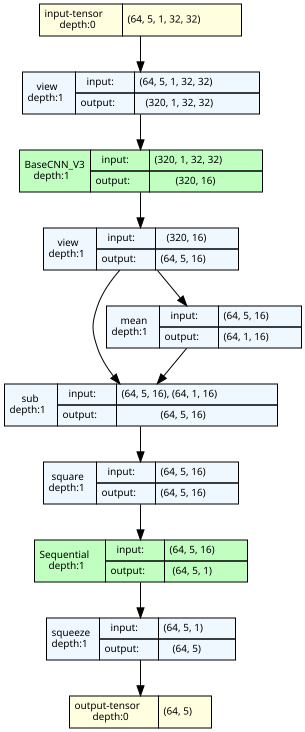

In [ ]:
from torchview import draw_graph
import graphviz
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

best_cnn_cfg = {
    'embedding_dim': 16,
    'distance_metric': 'l2',
    'classifier_type': 'mlp',
    'drop_percent': 0.20
}

base_cnn_untrained = BaseCNN_V3(embedding_dim=best_cnn_cfg['embedding_dim'])

untrained_siamese_model = SiameseNetwork(
    base_cnn=base_cnn_untrained,
    embedding_dim=best_cnn_cfg['embedding_dim'],
    classifier_type=best_cnn_cfg['classifier_type'],
    distance_metric=best_cnn_cfg['distance_metric'],
    drop_percent=best_cnn_cfg['drop_percent']
).to(device)

untrained_siamese_model.eval()

cnn_graph = draw_graph(
    untrained_siamese_model,
    input_size=(64, 5, 1, 32, 32),
    graph_name="Siamese_CNN_Architecture",
    depth=1,
    save_graph=True,
    filename="siamese_cnn_compact"
)

cnn_graph.visual_graph

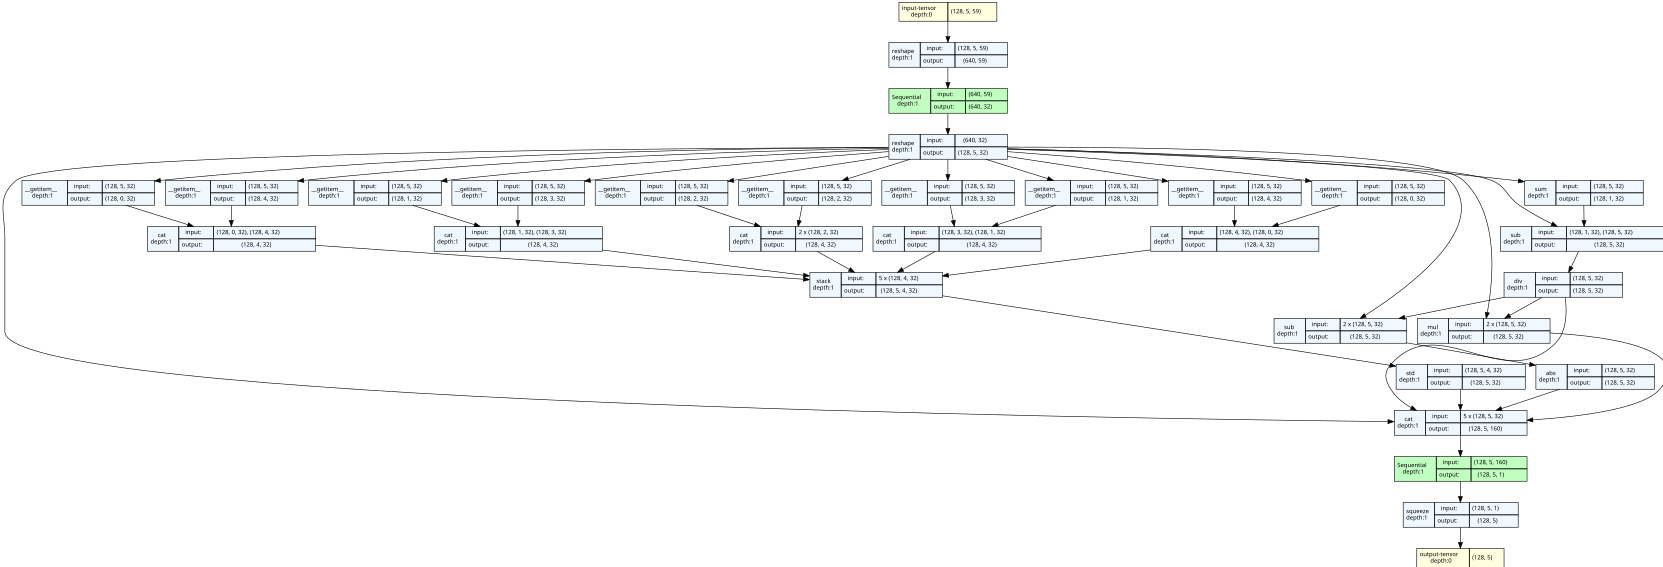

In [ ]:
from torchview import draw_graph
import graphviz

model.eval()

model_graph = draw_graph(
    model,
    input_size=(128, 5, feat_dim),
    graph_name="Geometric_MLP_Architecture",
    depth=1,
    save_graph=True,
    filename="geometric_mlp_compact"
)

model_graph.visual_graph